# 实验一：Python 基础编程实践

依照实验说明完成环境验证、Python 语法、NumPy、Pandas 清洗、可选绘图和四道思考题。
在 Jupyter 中选择 **Python (pppp 实验)**，然后“重启内核并运行全部”。原始 CSV 保持不变，结果保存到数据旁的 `output_lab1`。

本实验采用 Python 虚拟环境 + JupyterLab，满足实验的 Python / NumPy / Pandas 运行要求。

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

print('Python:', sys.version)
print('解释器:', sys.executable)
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)
print('Matplotlib:', matplotlib.__version__)
pd.set_option('display.max_columns', 12)

# 兼容从项目根目录或 Notebook 所在目录启动。
filename = '实验一_销售流水_原始.csv'
candidates = [Path.cwd() / filename,
              Path.cwd() / '实验一资料' / filename,
              Path.cwd() / '实验一资料' / '实验一资料' / filename]
data_path = next((p for p in candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError('请将 Notebook 和原始 CSV 放在同一文件夹，并从该目录启动 Jupyter。')
out_dir = data_path.parent / 'output_lab1'
out_dir.mkdir(exist_ok=True)
print('数据路径:', data_path.resolve())

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
解释器: c:\Users\LENOVN\Desktop\pppp\.venv\Scripts\python.exe
NumPy: 2.4.6
Pandas: 3.0.5
Matplotlib: 3.11.2
数据路径: C:\Users\LENOVN\Desktop\pppp\实验一资料\实验一资料\实验一_销售流水_原始.csv


## 任务一：Python 语法
摄氏温度转华氏温度；成绩分级；通过循环统计超过平均销售额的数量。

In [15]:
def celsius_to_fahrenheit(celsius):
    return celsius * 9 / 5 + 32

def score_to_grade(score):
    if not 0 <= score <= 100:
        raise ValueError('分数必须在 0～100 之间')
    if score >= 90:
        return 'A'
    elif score >= 80:
        return 'B'
    elif score >= 70:
        return 'C'
    elif score >= 60:
        return 'D'
    return 'F'

print('0℃ =', celsius_to_fahrenheit(0), '℉')
print('100℃ =', celsius_to_fahrenheit(100), '℉')
# 默认用示例分数，让“运行全部”无需等待输入；改为 True 可手动输入。
interactive = False
try:
    score = float(input('请输入分数（0～100）：')) if interactive else 85
    print(f'{score} 分对应等级：{score_to_grade(score)}')
except ValueError as exc:
    print('输入错误：', exc)

sales = [120, 880, 9980, 45, 320, 760]
average = sum(sales) / len(sales)
count = 0
for value in sales:
    if value > average:
        count += 1
print(f'平均销售额：{average:.2f}，超过均值的个数：{count}')
print('列表推导式结果：', [value for value in sales if value > average])

0℃ = 32.0 ℉
100℃ = 212.0 ℉
85 分对应等级：B
平均销售额：2017.50，超过均值的个数：1
列表推导式结果： [9980]


## 任务二：NumPy
固定随机种子使结果可以复现；`integers` 上界不包含在内，因此使用 101 来包含 100。标准差使用总体标准差（`ddof=0`）。

In [17]:
rng = np.random.default_rng(42)
arr = rng.integers(0, 101, size=(5, 5))
print('原数组：\n', arr)
print('形状：', arr.shape, '类型：', arr.dtype)
print('最大值：', arr.max(), '最小值：', arr.min())
print('均值：', arr.mean(), '标准差：', arr.std())
print('转置：\n', arr.T)
print('重塑为一维：', arr.reshape(-1))
print('每行均值：', arr.mean(axis=1))

原数组：
 [[ 9 78 66 44 43]
 [86  8 70 20  9]
 [53 98 74 76 72]
 [79 51 12 84 45]
 [50 37 18 93 78]]
形状： (5, 5) 类型： int64
最大值： 98 最小值： 8
均值： 54.12 标准差： 28.117354071818355
转置：
 [[ 9 86 53 79 50]
 [78  8 98 51 37]
 [66 70 74 12 18]
 [44 20 76 84 93]
 [43  9 72 45 78]]
重塑为一维： [ 9 78 66 44 43 86  8 70 20  9 53 98 74 76 72 79 51 12 84 45 50 37 18 93
 78]
每行均值： [48.  38.6 74.6 54.2 55.2]


## 任务三：Pandas 数据处理
### 1. 读取与概览
保留 `raw` 供追溯；数量与金额先按字符串读取，统一清理后再数值化。

In [18]:
raw = pd.read_csv(data_path, encoding='utf-8-sig', dtype='string')
print('原始形状：', raw.shape)
display(raw.head())
raw.info()
display(raw.isna().sum().rename('原始缺失数量').to_frame())

原始形状： (1012, 6)


,order_id,order_time,store,category,amount,quantity
0,D260301001,03-01-2026 09:42,B店,服饰,664.13,3
1,D260301002,2026-03-01 11:18:00,A店,服饰,320元,2
2,D260301003,2026/3/1 11:23,A店,家电,¥630.14,1
3,D260301004,2026-03-01 12:04:00,B店,家电,196元,2.0
4,D260301005,2026/3/1 15:28,A店,食品,574元,1


<class 'pandas.DataFrame'>
RangeIndex: 1012 entries, 0 to 1011
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   order_id    1012 non-null   string
 1   order_time  1012 non-null   string
 2   store       1002 non-null   string
 3   category    997 non-null    string
 4   amount      987 non-null    string
 5   quantity    991 non-null    string
dtypes: string(6)
memory usage: 47.6 KB


,原始缺失数量
order_id,0
order_time,0
store,10
category,15
amount,25
quantity,21


### 2. 检查并去重
本数据重复订单为整行重复。先按整行去重，再检查订单号是否仍有冲突，避免直接按订单号删除信息不一致的记录。

In [5]:
duplicate_count = int(raw.duplicated().sum())
print('完全重复的行数：', duplicate_count)
display(raw.loc[raw.duplicated(keep=False)].head(8))
df = raw.drop_duplicates().copy()
print('去重后的形状：', df.shape)
print('剩余重复订单号：', df['order_id'].duplicated().sum())
assert df['order_id'].is_unique, '存在内容不同的同订单号记录，需另行核对'

完全重复的行数： 12


,order_id,order_time,store,category,amount,quantity
139,D260314001,03-14-2026 10:46,B店,食品,¥220.52,<NA>
367,D260404004,04-04-2026 12:20,C店,家电,¥421.05,4.0
519,D260418010,2026-04-18 18:49:00,A店,服饰,¥419.04,1
622,D260428001,2026/4/28 11:07,C店,图书,¥641.49,3.0
634,D260429003,04-29-2026 13:32,C店,家电,558元,1.0
667,D260502005,05-02-2026 14:24,A店,图书,¥728.54,3.0
830,D260518003,05-18-2026 13:43,B店,图书,¥676.14,1.0
853,D260520004,05-20-2026 15:12,C店,食品,369元,6.0


去重后的形状： (1000, 6)
剩余重复订单号： 0


### 3. 类型转换，标签统一

- 金额去掉货币符号、千位逗号、空白和“元”，再转换成数值。
- 门店统一大小写、去空白，将“门店”统一成“店”；类别去空白和末尾的“类”。暂不转 `category`。
- PDF 明确短横线日期采用美式“月-日-年”，例如 `03-04-2026` 是 3 月 4 日。
  三种格式逐一解析，避免混合格式误判或把合法日期转成缺失。

In [ ]:
df['amount'] = pd.to_numeric(
    df['amount'].str.replace(r'[¥￥元,，\s]', '', regex=True), errors='coerce')

df['quantity'] = pd.to_numeric(df['quantity'], errors='coerce')

df['store'] = (df['store'].str.strip().str.upper()
               .str.replace('门店', '店', regex=False).replace('', pd.NA))

df['category'] = (df['category'].str.strip()
                  .str.replace(r'类$', '', regex=True).replace('', pd.NA))

time_text = df['order_time'].str.strip()
parsed = pd.Series(pd.NaT, index=df.index, dtype='datetime64[ns]')
for fmt in ['%Y-%m-%d %H:%M:%S', '%Y/%m/%d %H:%M', '%m-%d-%Y %H:%M']:
    parsed = parsed.fillna(pd.to_datetime(time_text, format=fmt, errors='coerce'))
df['order_time'] = parsed
print('无法解析的日期数：', parsed.isna().sum())
display(time_text[parsed.isna()].to_frame('需检查的时间'))
print('门店：', df['store'].unique())
print('类别：', df['category'].unique())
display(df.head())
df.info()

无法解析的日期数： 0


,需检查的时间


门店： <StringArray>
['B店', 'A店', 'C店', <NA>]
Length: 4, dtype: string
类别： <StringArray>
['服饰', '家电', '食品', '图书', <NA>]
Length: 5, dtype: string


,order_id,order_time,store,category,amount,quantity
0,D260301001,2026-03-01 09:42:00,B店,服饰,664.13,3.0
1,D260301002,2026-03-01 11:18:00,A店,服饰,320.0,2.0
2,D260301003,2026-03-01 11:23:00,A店,家电,630.14,1.0
3,D260301004,2026-03-01 12:04:00,B店,家电,196.0,2.0
4,D260301005,2026-03-01 15:28:00,A店,食品,574.0,1.0


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   order_id    1000 non-null   string        
 1   order_time  1000 non-null   datetime64[ns]
 2   store       990 non-null    string        
 3   category    985 non-null    string        
 4   amount      975 non-null    Float64       
 5   quantity    980 non-null    Float64       
dtypes: Float64(2), datetime64[ns](1), string(3)
memory usage: 49.0 KB


### 4. 筛选与初步月度统计
这里按照实验步骤演示清洗前的查询，仍含异常值，不能作为最终业务结论。最终月销量将在处理完缺失与异常后重新计算；销量取 `quantity` 之和，不是订单数。

In [7]:
monthly_before = df.groupby(df['order_time'].dt.to_period('M'))['quantity'].sum(min_count=1)
display(monthly_before.rename('清洗前月销量').to_frame())
large_before = df.loc[df['amount'] > 1000]
print('amount > 1000 的订单数：', len(large_before))
display(large_before)
a_appliance_before = df.query("store == 'A店' and category == '家电'")
print('A店家电订单数：', len(a_appliance_before))
display(a_appliance_before.head())

,清洗前月销量
order_time,
2026-03,920.0
2026-04,815.0
2026-05,963.0
2026-06,70.0


amount > 1000 的订单数： 3


,order_id,order_time,store,category,amount,quantity
486,D260415006,2026-04-15 15:37:00,C店,服饰,999999.0,2.0
601,D260426005,2026-04-26 15:47:00,B店,图书,88888.0,3.0
770,D260512008,2026-05-12 16:59:00,A店,家电,77777.0,1.0


A店家电订单数： 172


,order_id,order_time,store,category,amount,quantity
2,D260301003,2026-03-01 11:23:00,A店,家电,630.14,1.0
19,D260302009,2026-03-02 21:05:00,A店,家电,629.06,3.0
22,D260303002,2026-03-03 09:23:00,A店,家电,400.96,5.0
25,D260303005,2026-03-03 14:10:00,A店,家电,324.51,1.0
29,D260304001,2026-03-04 09:10:00,A店,家电,725.28,1.0


### 5. 缺失值检测与填充

金额使用中位数，数量使用正整数样本的中位数；门店、类别填“未知”。
为避免异常值影响填充基准，先计算金额 IQR 候选范围，使用范围内非负金额的中位数。
此处只填原有缺失，异常值保留至下一步单独展示和处理。记录填充标记，方便追溯估计值。

In [8]:
typed = df.copy()
missing_before = df.isna().sum()
display(missing_before.rename('填充前缺失数量').to_frame())
q1, q3 = df['amount'].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
amount_reference = df.loc[df['amount'].ge(0) & df['amount'].between(lower, upper), 'amount']
quantity_reference = df.loc[df['quantity'].gt(0) & df['quantity'].mod(1).eq(0), 'quantity']
amount_median = float(amount_reference.median())
quantity_median = float(quantity_reference.median())
print(f'IQR 下界：{lower:.2f}，上界：{upper:.2f}')
print('金额填充值：', amount_median, '数量填充值：', quantity_median)
fill_flags = df[['order_id']].copy()
for col in ['amount', 'quantity', 'store', 'category']:
    fill_flags[col + '_was_missing'] = df[col].isna()
df['amount'] = df['amount'].fillna(amount_median)
df['quantity'] = df['quantity'].fillna(quantity_median)
df['store'] = df['store'].fillna('未知')
df['category'] = df['category'].fillna('未知')
display(pd.DataFrame({'填充前': missing_before, '填充后': df.isna().sum()}))

,填充前缺失数量
order_id,0
order_time,0
store,10
category,15
amount,25
quantity,20


IQR 下界：-339.28，上界：1135.11
金额填充值： 410.155 数量填充值： 2.0


,填充前,填充后
order_id,0,0
order_time,0,0
store,10,0
category,15,0
amount,25,0
quantity,20,0


### 6. 异常值检测与处理

IQR 只用于筛查候选异常，不能单凭“大额”认定错误。本数据的实验说明已明确列出 8 个金额负值、
3 个离谱极值（999999、88888、77777），以及数量的 5 个 0 和 3 个 -1。
本次按普通正向销售流水口径，将负金额、非正/非整数数量、说明中列明的三个极值隔离，
导出异常明细后从分析数据剔除整笔订单，不猜测正确金额。其他 IQR 候选只标记、不自动删除。
实际业务若包含退款，负金额应先核对退款标记再分类处理。

In [9]:
negative = df['amount'] < 0
iqr_candidate = ~df['amount'].between(lower, upper)
known_extreme = df['amount'].isin([999999, 88888, 77777])
invalid_quantity = (df['quantity'] <= 0) | (df['quantity'] % 1 != 0)
invalid_time = df['order_time'].isna()
print('负金额：', int(negative.sum()))
print('IQR 候选数：', int(iqr_candidate.sum()))
print('实验说明列明极值：', int(known_extreme.sum()))
print('数量为 0：', int(df['quantity'].eq(0).sum()), '数量为负：', int(df['quantity'].lt(0).sum()))
display(df.loc[iqr_candidate | negative | invalid_quantity])
bad = negative | known_extreme | invalid_quantity | invalid_time
reasons = pd.Series('', index=df.index, dtype='string')
for mask, reason in [(negative, '金额为负;'), (known_extreme, '实验列明极端金额;'),
                     (invalid_quantity, '数量非正整数;'), (invalid_time, '时间解析失败;')]:
    reasons.loc[mask] = reasons.loc[mask] + reason
anomalies = typed.loc[bad].copy()
anomalies['异常原因'] = reasons.loc[bad]
anomalies['原始金额文本'] = raw.loc[bad.index[bad], 'amount']
anomalies['原始时间文本'] = raw.loc[bad.index[bad], 'order_time']
display(anomalies)
clean = df.loc[~bad].copy()
clean['quantity'] = clean['quantity'].astype('int64')
for col in ['store', 'category']:
    clean[col] = clean[col].astype('category')
print(f'去重后 {len(df)} 行，隔离异常 {int(bad.sum())} 行，最终 {len(clean)} 行。')

负金额： 8
IQR 候选数： 3
实验说明列明极值： 3
数量为 0： 5 数量为负： 3


,order_id,order_time,store,category,amount,quantity
34,D260304006,2026-03-04 13:35:00,A店,服饰,-260.0,2.0
78,D260308003,2026-03-08 11:47:00,A店,食品,-260.0,3.0
116,D260311010,2026-03-11 20:47:00,A店,食品,101.0,-1.0
133,D260313008,2026-03-13 14:49:00,C店,图书,-80.0,1.0
222,D260321006,2026-03-21 18:38:00,B店,家电,-199.0,4.0
284,D260327011,2026-03-27 20:33:00,C店,家电,-50.0,3.0
401,D260407006,2026-04-07 11:24:00,C店,家电,672.89,0.0
415,D260408009,2026-04-08 14:47:00,A店,食品,83.0,0.0
486,D260415006,2026-04-15 15:37:00,C店,服饰,999999.0,2.0
488,D260415008,2026-04-15 18:17:00,B店,图书,-199.0,4.0


,order_id,order_time,store,category,amount,quantity,异常原因,原始金额文本,原始时间文本
34,D260304006,2026-03-04 13:35:00,A店,服饰,-260.0,2.0,金额为负;,¥-260.00,03-04-2026 13:35
78,D260308003,2026-03-08 11:47:00,A店,食品,-260.0,3.0,金额为负;,-260.00,2026/3/8 11:47
116,D260311010,2026-03-11 20:47:00,A店,食品,101.0,-1.0,数量非正整数;,101元,03-11-2026 20:47
133,D260313008,2026-03-13 14:49:00,C店,图书,-80.0,1.0,金额为负;,¥-80.00,2026/3/13 14:49
222,D260321006,2026-03-21 18:38:00,B店,家电,-199.0,4.0,金额为负;,¥-199.00,03-21-2026 18:38
284,D260327011,2026-03-27 20:33:00,C店,家电,-50.0,3.0,金额为负;,¥-50.00,03-27-2026 20:33
401,D260407006,2026-04-07 11:24:00,C店,家电,672.89,0.0,数量非正整数;,¥672.89,2026-04-07 11:24:00
415,D260408009,2026-04-08 14:47:00,A店,食品,83.0,0.0,数量非正整数;,83元,2026-04-08 14:47:00
486,D260415006,2026-04-15 15:37:00,C店,服饰,999999.0,2.0,实验列明极端金额;,999999元,2026/4/15 15:37
488,D260415008,2026-04-15 18:17:00,B店,图书,-199.0,4.0,金额为负;,¥-199.00,2026-04-15 18:17:00


去重后 1000 行，隔离异常 19 行，最终 981 行。


### 7. 最终聚合与透视
按门店统计销售总额、平均订单额、订单笔数、销量；透视表展示“门店 × 类别”的销售金额。未知门店单列，不分配给 A/B/C 店。

In [10]:
store_summary = clean.groupby('store', observed=True).agg(
    销售总额=('amount', 'sum'), 平均订单额=('amount', 'mean'),
    订单笔数=('order_id', 'count'), 销量=('quantity', 'sum')).round(2)
pivot = clean.pivot_table(index='store', columns='category', values='amount',
                          aggfunc='sum', fill_value=0, margins=True,
                          margins_name='合计', observed=True).round(2)
monthly = clean.groupby(clean['order_time'].dt.to_period('M')).agg(
    销量=('quantity', 'sum'), 销售额=('amount', 'sum'), 订单数=('order_id', 'count'))
monthly['销售额'] = monthly['销售额'].round(2)
display(store_summary)
display(pivot)
display(monthly)
print('清洗后 amount > 1000 的订单数：', len(clean.query('amount > 1000')))
display(clean.query("store == 'A店' and category == '家电'").head())

,销售总额,平均订单额,订单笔数,销量
store,,,,
A店,146418.35,400.05,366,1042
B店,138764.8,419.23,331,928
C店,109636.59,400.13,274,787
未知,3240.68,324.07,10,21


category,图书,家电,服饰,未知,食品,合计
store,,,,,,
A店,22607.08,69474.98,30658.98,1844.59,21832.73,146418.35
B店,54944.14,23227.66,28112.36,2322.26,30158.38,138764.8
C店,22193.57,35565.4,26139.2,1542.24,24196.18,109636.59
未知,1071.61,986.12,932.18,0.0,250.77,3240.68
合计,100816.39,129254.16,85842.72,5709.09,76438.06,398060.42


,销量,销售额,订单数
order_time,,,
2026-03,920,129469.68,327
2026-04,825,124740.48,310
2026-05,959,132687.08,318
2026-06,74,11163.19,26


清洗后 amount > 1000 的订单数： 0


,order_id,order_time,store,category,amount,quantity
2,D260301003,2026-03-01 11:23:00,A店,家电,630.14,1
19,D260302009,2026-03-02 21:05:00,A店,家电,629.06,3
22,D260303002,2026-03-03 09:23:00,A店,家电,400.96,5
25,D260303005,2026-03-03 14:10:00,A店,家电,324.51,1
29,D260304001,2026-03-04 09:10:00,A店,家电,725.28,1


### 8. 验证并保存
CSV 使用 `index=False` 和 `utf-8-sig`。聚合结果先 `reset_index()`，确保门店和月份不会随索引一起丢失。保存后重新读回，验证行数与数值。

In [11]:
assert clean['order_id'].is_unique
assert not clean.isna().any().any()
assert clean['amount'].ge(0).all()
assert clean['quantity'].gt(0).all()
assert len(raw) == duplicate_count + len(anomalies) + len(clean)
assert int(store_summary['订单笔数'].sum()) == len(clean)
assert int(monthly['销量'].sum()) == int(clean['quantity'].sum())
# 本数据订单号包含 YYMMDD，可交叉验证混合日期没有日/月颠倒。
id_dates = pd.to_datetime(clean['order_id'].str.slice(1, 7), format='%y%m%d')
assert clean['order_time'].dt.normalize().eq(id_dates).all()

outputs = {
    '销售流水_清洗后.csv': clean,
    '异常订单明细.csv': anomalies,
    '缺失填充记录.csv': fill_flags,
    '门店销售汇总.csv': store_summary.reset_index(),
    '门店类别透视.csv': pivot.reset_index(),
    '月度销售汇总.csv': monthly.reset_index(),
}
for name, table in outputs.items():
    table.to_csv(out_dir / name, index=False, encoding='utf-8-sig')
saved = pd.read_csv(out_dir / '销售流水_清洗后.csv', encoding='utf-8-sig')
assert len(saved) == len(clean)
assert list(saved.columns) == list(raw.columns)
assert np.allclose(saved['amount'], clean['amount'].astype(float))
print('验证通过，输出目录：', out_dir.resolve())
display(clean.head())
display(clean.isna().sum().rename('最终缺失数量').to_frame())

验证通过，输出目录： C:\Users\LENOVN\Desktop\pppp\实验一资料\实验一资料\output_lab1


,order_id,order_time,store,category,amount,quantity
0,D260301001,2026-03-01 09:42:00,B店,服饰,664.13,3
1,D260301002,2026-03-01 11:18:00,A店,服饰,320.0,2
2,D260301003,2026-03-01 11:23:00,A店,家电,630.14,1
3,D260301004,2026-03-01 12:04:00,B店,家电,196.0,2
4,D260301005,2026-03-01 15:28:00,A店,食品,574.0,1


,最终缺失数量
order_id,0
order_time,0
store,0
category,0
amount,0
quantity,0


## 任务四：各门店销售额柱状图（选做）
优先使用 Windows 的微软雅黑或黑体，避免中文乱码。图形同时保存成 PNG。

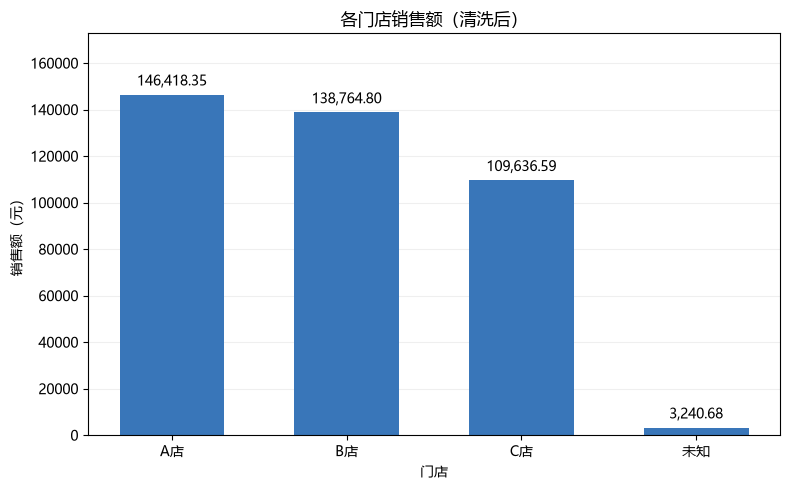

In [12]:
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
chinese_fonts = [name for name in ['Microsoft YaHei', 'SimHei', 'SimSun',
                                  'Noto Sans CJK SC'] if name in available_fonts]
if not chinese_fonts:
    raise RuntimeError('未找到中文字体，请安装微软雅黑或 Noto Sans CJK SC 后重启内核。')
plt.rcParams['font.sans-serif'] = chinese_fonts
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(8, 5))
values = store_summary['销售总额'].astype(float)
bars = ax.bar(store_summary.index.astype(str), values, color='#3976B9', width=0.6)
ax.bar_label(bars, labels=[f'{value:,.2f}' for value in values], padding=4, fontsize=10)
ax.set(title='各门店销售额（清洗后）', xlabel='门店', ylabel='销售额（元）')
ax.set_ylim(0, values.max() * 1.18)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(out_dir / '各门店销售额.png', dpi=160, bbox_inches='tight')
plt.show()

## 思考题

**1. 为什么缺失值常用中位数而非均值？**

均值会随数值大小变化，对极端值敏感；中位数主要取决于排序位置，较稳健。
本数据去重后有 8 个金额负值和 3 个极端金额，特别是 999999 会明显拉高均值。
用这样的均值填充会把缺失订单金额高估。因此先识别异常，再用合理样本中位数填充。
中位数填充仍是估计，会减少数据变异、影响汇总，不能当作已核实的实际金额。

In [13]:
comparison = pd.DataFrame({
    '包含异常的非空金额': [typed['amount'].mean(), typed['amount'].median()],
    '非负且在IQR范围内的金额': [amount_reference.mean(), amount_reference.median()],
}, index=['均值', '中位数']).round(2)
display(comparison)

,包含异常的非空金额,非负且在IQR范围内的金额
均值,1595.69,405.07
中位数,408.59,410.16


**2. IQR 法则与 3σ 法则分别适用于什么分布？为什么推荐 IQR？**

3σ 以均值加减三倍标准差为界，主要适合近似正态分布；正态情况下约 99.73% 的数据位于此区间。
极端值会同时拉动均值和标准差，导致异常掩盖。IQR 使用 Q1、Q3 和四分位距，
不要求数据服从正态分布，对极端值更稳健，适合本例有污染的销售流水。
但偏态、长尾分布也可能把合理大额订单标为 IQR 候选，必须结合业务判断，不能机械删除。

**3. NumPy 向量化与 Python 列表循环的内存、速度差异？为什么 pandas 依赖 NumPy？**

普通 Python 数值列表保存对象引用，数值对象本身另占内存；Python 循环逐项解释执行，有类型检查和循环开销。
NumPy 同类型数组使用紧凑的数据缓冲区（视图不一定连续），底层编译代码批量执行运算，
通常有更好的缓存利用率，也能利用 SIMD 等优化。因此大规模同类型数值运算一般更省内存、更快。
向量化也可能产生临时数组，并非所有小规模任务都更快。pandas 利用 NumPy 的数组、广播和计算能力，
在其上提供标签、索引和分组等操作；现代 pandas 也支持扩展类型及 Arrow，不能说所有列都只由 NumPy 存储。

**4. 为什么保存 CSV 推荐 `index=False`、中文用 `utf-8-sig`？**

`index=False` 避免将无业务意义的 DataFrame 行号写入文件，防止重新读取时出现 `Unnamed: 0` 列。
如果索引代表门店、月份等业务字段，应先 `reset_index()` 保留它们。
`utf-8-sig` 在 UTF-8 文件头加入 BOM，帮助 Windows Excel 等软件识别编码，降低中文乱码风险；
它不是 CSV 必须的编码，而是便于本次 Windows 环境下交换数据的选择。